In [2]:
# Версия Python нужна для проверки совместимости зависимостей.
import sys
print(sys.version)

# Проверяем модель видеокарты и доступную видеопамять.
!nvidia-smi


3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Wed Nov  4 06:03:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A

Зависимости окружения

In [3]:
# uv — инструмент для создания окружения и установки библиотек.
%pip install -q uv

# Создаём отдельное окружение для лабораторной.
!uv venv --python python3 /content/lab1-env

# Устанавливаем сервер и клиент.
# Подходящую сборку PyTorch установщик подберёт автоматически.
!uv pip install --python /content/lab1-env/bin/python vllm openai --torch-backend=auto

Using CPython 3.13.16 interpreter at: /usr/bin/python3
Creating virtual environment at: lab1-env
Activate with: source lab1-env/bin/activate
Using Python 3.13.16 environment at: lab1-env
Resolved 199 packages in 2.00s
Prepared 199 packages in 1m 42s
Installed 199 packages in 1.80s
 + agent-detector==2.0.0
 + aiohappyeyeballs==2.7.1
 + aiohttp==3.14.5
 + aiosignal==1.4.0
 + annotated-doc==0.0.5
 + annotated-types==0.8.0
 + anthropic==2.4.0
 + anyio==4.16.0
 + apache-tvm-ffi==0.1.11
 + astor==0.8.1
 + attrs==26.1.0
 + blake3==1.0.11
 + cachetools==7.2.8
 + cbor2==6.2.0.post2
 + certifi==2026.10.23
 + cffi==2.1.1
 + charset-normalizer==3.5.2
 + click==8.5.0
 + cloudpickle==3.1.2
 + compressed-tensors==0.17.0
 + cryptography==50.0.2
 + cuda-bindings==13.4.4
 + cuda-core==1.2.2
 + cuda-pathfinder==1.8.5
 + cuda-python==13.4.4
 + cuda-tile==1.7.0
 + cuda-toolkit==13.2.1
 + depyf==0.20.0
 + detect-installer==0.2.1
 + dill==0.4.1
 + dnspython==2.9.2
 + docstring-parser==0.18.0
 + einops==0.8.2

In [4]:
# Проверяем установленные версии и доступность видеокарты.
import subprocess

check_code = """
import torch
from importlib.metadata import version

print("vLLM:", version("vllm"))
print("OpenAI client:", version("openai"))
print("PyTorch:", torch.__version__)
print("CUDA в PyTorch:", torch.version.cuda)
print("GPU доступна:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Видеокарта:", torch.cuda.get_device_name(0))
"""

subprocess.run(
    ["/content/lab1-env/bin/python", "-c", check_code],
    check=True,
)

CompletedProcess(args=['/content/lab1-env/bin/python', '-c', '\nimport torch\nfrom importlib.metadata import version\n\nprint("vLLM:", version("vllm"))\nprint("OpenAI client:", version("openai"))\nprint("PyTorch:", torch.__version__)\nprint("CUDA в PyTorch:", torch.version.cuda)\nprint("GPU доступна:", torch.cuda.is_available())\n\nif torch.cuda.is_available():\n    print("Видеокарта:", torch.cuda.get_device_name(0))\n'], returncode=0)

Запуск сервера модели

In [5]:
# Загружаем Qwen и запускаем сервер в фоне.
# Выполни эту ячейку один раз: второй экземпляр займёт ту же видеопамять.
import subprocess
from pathlib import Path

MODEL = "Qwen/Qwen3-4B-Instruct-2507"
LOG_PATH = Path("/content/vllm.log")

command = [
    "/content/lab1-env/bin/vllm", "serve", MODEL,
    "--dtype", "half",                   # Веса в FP16.
    "--max-model-len", "32768",          # Общий предел запроса и ответа.
    "--max-num-seqs", "32",              # До 32 активных последовательностей.
    "--gpu-memory-utilization", "0.90",  # Бюджет — 90% видеопамяти.
    "--no-enable-prefix-caching",        # Для первого опыта кеш префикса отключён.
    "--enable-auto-tool-choice",
    "--tool-call-parser", "hermes",
    "--host", "127.0.0.1",               # Доступ внутри этой среды Colab.
    "--port", "8000",
]

# Сохраняем команду для будущего паспорта сервера.
Path("/content/server_command.txt").write_text(
    " ".join(command), encoding="utf-8"
)

with LOG_PATH.open("w", encoding="utf-8") as log:
    server_process = subprocess.Popen(
        command, stdout=log, stderr=subprocess.STDOUT
    )

print("Процесс запущен, PID:", server_process.pid)
print("Журнал:", LOG_PATH)

Процесс запущен, PID: 3030
Журнал: /content/vllm.log


Проверка готовности

In [11]:
# Показываем последние сообщения сервера.
print(LOG_PATH.read_text(encoding="utf-8", errors="replace")[-8000:])

# Проверяем, появился ли работающий API.
import json
import urllib.request
import urllib.error

try:
    with urllib.request.urlopen(
        "http://127.0.0.1:8000/v1/models", timeout=5
    ) as response:
        models = json.load(response)

    print("\nСЕРВЕР ГОТОВ")
    print("Модели:", [item["id"] for item in models["data"]])

except urllib.error.URLError:
    print("\nСервер пока не отвечает.")
    print("Статус процесса:", server_process.poll())
    # None — процесс ещё работает; число — процесс завершился.

to 0.9087. To disable, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=0.
(EngineCore pid=3310) INFO 11-04 06:09:31 [kv_cache_utils.py:1147] GPU KV cache size: 33,136 tokens, Maximum concurrency for 32,768 tokens per request: 1.01x
(EngineCore pid=3310) INFO 11-04 06:09:31 [kernel_warmup.py:179] JIT kernel warmup starting.
(EngineCore pid=3310) INFO 11-04 06:09:31 [kernel_warmup.py:192] JIT kernel warmup finished in 0.00s.

Capturing CUDA graphs (PIECEWISE): 100%|██████████| 11/11 [00:01<00:00, 10.49it/s]

Capturing CUDA graphs (FULL): 100%|██████████| 7/7 [00:00<00:00, 15.21it/s]
(EngineCore pid=3310) INFO 11-04 06:09:42 [model_runner.py:1163] Graph capturing finished in 3 secs, took 0.07 GiB
(EngineCore pid=3310) INFO 11-04 06:09:42 [gpu_worker.py:1003] CUDA graph pool memory: 0.07 GiB (actual), 0.13 GiB (estimated), difference: 0.06 GiB (91.2%).
(EngineCore pid=3310) INFO 11-04 06:09:42 [gpu_worker.py:1066] Free memory on device (14.41/14.56 GiB) on startup. Desired GPU memory utilizat

Проверка обязательного условия: модель должна выдать ровно 64 токена.

In [12]:
# Код выполняется в окружении, где установлен клиент openai.
test_code = """
from openai import OpenAI
from pathlib import Path

client = OpenAI(
    base_url="http://127.0.0.1:8000/v1",
    api_key="none",
    timeout=180,
)

response = client.chat.completions.create(
    model="Qwen/Qwen3-4B-Instruct-2507",
    messages=[
        {"role": "user", "content": "Explain what a language model is."}
    ],
    temperature=0,
    top_p=1,
    presence_penalty=0,
    frequency_penalty=0,
    max_tokens=64,
    extra_body={
        "ignore_eos": True,
        "top_k": -1,
        "repetition_penalty": 1.0,
    },
)

# Сохраняем ответ вместе с фактическим количеством токенов.
folder = Path("/content/lab1_artifacts")
folder.mkdir(exist_ok=True)
(folder / "check_64_tokens.json").write_text(
    response.model_dump_json(indent=2), encoding="utf-8"
)

print("Ответ:", response.choices[0].message.content)
print("Токенов запроса:", response.usage.prompt_tokens)
print("Токенов ответа:", response.usage.completion_tokens)
print("Причина завершения:", response.choices[0].finish_reason)

assert response.usage.completion_tokens == 64, "Длина ответа отличается от 64"
print("ПРОВЕРКА ПРОЙДЕНА")
"""

# Явно получаем вывод процесса и показываем его в блокноте.
test_result = subprocess.run(
    ["/content/lab1-env/bin/python", "-c", test_code],
    capture_output=True,
    text=True,
)

print(test_result.stdout)

if test_result.stderr:
    print(test_result.stderr)

test_result.check_returncode()

Ответ: A **language model** is a type of artificial intelligence (AI) system designed to understand, generate, and predict human language. At its core, a language model learns patterns in large amounts of text data—such as books, articles, websites, or conversations—so it can predict the next word or phrase in a
Токенов запроса: 16
Токенов ответа: 64
Причина завершения: length
ПРОВЕРКА ПРОЙДЕНА



In [13]:
# Читаем результат проверки без повторного запроса к модели.
import json
from pathlib import Path

result = json.loads(
    Path("/content/lab1_artifacts/check_64_tokens.json")
    .read_text(encoding="utf-8")
)

print("Ответ модели:")
print(result["choices"][0]["message"]["content"])

print("\nТокенов ответа:", result["usage"]["completion_tokens"])

Ответ модели:
A **language model** is a type of artificial intelligence (AI) system designed to understand, generate, and predict human language. At its core, a language model learns patterns in large amounts of text data—such as books, articles, websites, or conversations—so it can predict the next word or phrase in a

Токенов ответа: 64


Следующая обязательная проверка — совпадают ли ответы на одинаковые запросы при температуре 0.

In [14]:
repeat_code = """
import json
from pathlib import Path
from uuid import uuid4
from openai import OpenAI

client = OpenAI(
    base_url="http://127.0.0.1:8000/v1",
    api_key="none",
    timeout=180,
)

# Два последовательных запроса с одинаковыми параметрами.
responses = [
    client.chat.completions.create(
        model="Qwen/Qwen3-4B-Instruct-2507",
        messages=[
            {"role": "user", "content": "Explain what a language model is."}
        ],
        temperature=0,
        top_p=1,
        presence_penalty=0,
        frequency_penalty=0,
        max_tokens=64,
        extra_body={
            "ignore_eos": True,
            "top_k": -1,
            "repetition_penalty": 1.0,
        },
    )
    for _ in range(2)
]

texts = [r.choices[0].message.content for r in responses]
same = texts[0] == texts[1]

# Уникальное имя сохраняет результаты предыдущих проверок.
path = Path("/content/lab1_artifacts") / f"repeat_{uuid4().hex}.json"
path.write_text(
    json.dumps(
        {
            "texts_equal": same,
            "responses": [r.model_dump() for r in responses],
        },
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

print("Ответ 1:", texts[0])
print("Ответ 2:", texts[1])
print("Тексты совпали:", same)
print("Сохранено:", path)
"""

repeat_result = subprocess.run(
    ["/content/lab1-env/bin/python", "-c", repeat_code],
    capture_output=True,
    text=True,
)

print(repeat_result.stdout)
if repeat_result.stderr:
    print(repeat_result.stderr)
repeat_result.check_returncode()

Ответ 1: A **language model** is a type of artificial intelligence (AI) system designed to understand, generate, and predict human language. At its core, a language model learns patterns in large amounts of text data—such as books, articles, websites, or conversations—so it can predict the next word or phrase in a
Ответ 2: A **language model** is a type of artificial intelligence (AI) system designed to understand, generate, and predict human language. At its core, a language model learns patterns in large amounts of text data—such as books, articles, websites, or conversations—so it can predict the next word or phrase in a
Тексты совпали: True
Сохранено: /content/lab1_artifacts/repeat_6c6ccf3638c04098bf784a4bc1d9a968.json



Пробное измерение потокового ответа:

In [15]:
timing_code = """
import json
import time
from pathlib import Path
from uuid import uuid4
from openai import OpenAI

client = OpenAI(
    base_url="http://127.0.0.1:8000/v1",
    api_key="none",
    timeout=180,
)

text_parts = []
timestamps = []
usage = None
finish_reason = None

# Начало измерения — непосредственно перед отправкой запроса.
t0 = time.perf_counter()

stream = client.chat.completions.create(
    model="Qwen/Qwen3-4B-Instruct-2507",
    messages=[
        {"role": "user", "content": "Explain what a language model is."}
    ],
    temperature=0,
    top_p=1,
    presence_penalty=0,
    frequency_penalty=0,
    max_tokens=64,
    stream=True,
    stream_options={"include_usage": True},
    extra_body={
        "ignore_eos": True,
        "top_k": -1,
        "repetition_penalty": 1.0,
    },
)

for chunk in stream:
    if chunk.usage is not None:
        usage = chunk.usage

    if chunk.choices:
        choice = chunk.choices[0]

        if choice.finish_reason is not None:
            finish_reason = choice.finish_reason

        # Пустые служебные фрагменты не считаем появлением текста.
        if choice.delta.content:
            timestamps.append(time.perf_counter())
            text_parts.append(choice.delta.content)

if usage is None or not timestamps:
    raise RuntimeError("Не получены текст или сведения о токенах")

n = usage.completion_tokens
assert n == 64, f"Получено {n} токенов вместо 64"

t1, t_last = timestamps[0], timestamps[-1]

result = {
    "status": "completed",
    "kind": "timing_check",
    "t0": t0,
    "text_chunk_times": timestamps,
    "text_chunks": text_parts,
    "prompt_tokens": usage.prompt_tokens,
    "output_tokens": n,
    "ttft_s": t1 - t0,
    "tpot_s": (t_last - t1) / (n - 1),
    "e2e_s": t_last - t0,
    "finish_reason": finish_reason,
    "text": "".join(text_parts),
}

path = Path("/content/lab1_artifacts") / f"timing_{uuid4().hex}.json"
path.write_text(
    json.dumps(result, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("Ответ:", result["text"])
print(f"TTFT: {result['ttft_s'] * 1000:.2f} мс")
print(f"TPOT: {result['tpot_s'] * 1000:.2f} мс/токен")
print(f"Полное время: {result['e2e_s']:.3f} с")
print("Токенов ответа:", n)
print("Сохранено:", path)
"""

timing_result = subprocess.run(
    ["/content/lab1-env/bin/python", "-c", timing_code],
    capture_output=True,
    text=True,
)

print(timing_result.stdout)
if timing_result.stderr:
    print(timing_result.stderr)
timing_result.check_returncode()

Ответ: A **language model** is a type of artificial intelligence (AI) system designed to understand, generate, and predict human language. At its core, a language model learns patterns in large amounts of text data—such as books, articles, websites, or conversations—so it can predict the next word or phrase in a
TTFT: 154.13 мс
TPOT: 39.89 мс/токен
Полное время: 2.667 с
Токенов ответа: 64
Сохранено: /content/lab1_artifacts/timing_e88b990599024199acb09b8055c40f7d.json



Перед основными экспериментами сохраним текущие материалы, поскольку файлы в /content исчезнут после удаления среды Colab.

In [16]:
# Сохраняем зависимости, журналы и результаты проверок в архив.
import subprocess
import zipfile
from pathlib import Path
from datetime import datetime, timezone
from google.colab import files

artifacts = Path("/content/lab1_artifacts")

# Фиксируем фактически установленные версии библиотек.
freeze = subprocess.run(
    ["uv", "pip", "freeze", "--python", "/content/lab1-env/bin/python"],
    capture_output=True,
    text=True,
    check=True,
)
(artifacts / "requirements_colab.txt").write_text(
    freeze.stdout, encoding="utf-8"
)

# Каждый архив получает новое имя.
stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
archive = Path(f"/content/lab1_checkpoint_{stamp}.zip")

with zipfile.ZipFile(archive, "x", zipfile.ZIP_DEFLATED) as z:
    for path in artifacts.rglob("*"):
        if path.is_file():
            z.write(path, path.relative_to("/content"))

    for name in ["vllm.log", "server_command.txt"]:
        path = Path("/content") / name
        z.write(path, name)

print("Сохранено:", archive)
files.download(str(archive))

Сохранено: /content/lab1_checkpoint_20261104_061218_124650.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Теперь подготовим данные для запросов: книгу «Гордость и предубеждение» Джейн Остин из Project Gutenberg, как требует методичка.

Сохраним исходный текст и манифест с источником и SHA-256. Контрольная сумма позволит проверять, что во всех опытах использован один и тот же файл.

In [17]:
# Подготовка исходного текста для лабораторной.
# Здесь достаточно стандартных библиотек обычной среды Colab.
import hashlib
import json
import urllib.request
from pathlib import Path

data_dir = Path("/content/lab1_artifacts/data")
data_dir.mkdir(parents=True, exist_ok=True)

book_path = data_dir / "pride_and_prejudice.txt"
url = "https://www.gutenberg.org/cache/epub/1342/pg1342.txt"

# При повторном запуске используем уже сохранённый файл.
if not book_path.exists():
    with urllib.request.urlopen(url, timeout=60) as response:
        raw = response.read()

    # Проверяем кодировку до сохранения.
    raw.decode("utf-8-sig")
    book_path.write_bytes(raw)

# Хешируем именно сохранённые байты.
raw = book_path.read_bytes()
text = raw.decode("utf-8-sig")
book_hash = hashlib.sha256(raw).hexdigest()

# Защита от случайного сохранения страницы ошибки вместо книги.
if "PRIDE AND PREJUDICE" not in text.upper():
    raise ValueError("В файле не обнаружено название книги")

manifest = {
    "title": "Pride and Prejudice",
    "author": "Jane Austen",
    "source": "Project Gutenberg, ebook 1342",
    "source_url": url,
    "file": book_path.name,
    "encoding": "utf-8-sig",
    "bytes": len(raw),
    "sha256": book_hash,
    "selection_rule": "Сохранён полный исходный файл без изменений",
}

(data_dir / "manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("Файл:", book_path)
print("Размер:", len(raw), "байт")
print("SHA-256:", book_hash)
print("Манифест сохранён.")

Файл: /content/lab1_artifacts/data/pride_and_prejudice.txt
Размер: 772386 байт
SHA-256: 3f6bb9d6f78e0293b56acd4714dd68cb7d6d1d293402031ce9d5a216bcaf9d75
Манифест сохранён.


Теперь создадим запросы для первого эксперимента: длиной 256, 1024, 4096, 8192 и 16 384 токена, по пять запросов на каждую длину.

В длину входят уникальная метка, инструкция, текст книги и служебный шаблон диалога. Для подсчёта используем токенизатор Qwen и её шаблон диалога.

In [18]:
prepare_code = r'''
# Создаёт 25 запросов заданной длины, не запуская генерацию ответов.
import hashlib
import json
from pathlib import Path
from uuid import uuid4
from transformers import AutoTokenizer

ROOT = Path("/content/lab1_artifacts")
DATA = ROOT / "data"
MODEL = "Qwen/Qwen3-4B-Instruct-2507"

# Проверяем, что исходный файл книги не изменился.
raw = (DATA / "pride_and_prejudice.txt").read_bytes()
manifest = json.loads((DATA / "manifest.json").read_text(encoding="utf-8"))
assert hashlib.sha256(raw).hexdigest() == manifest["sha256"]

text = raw.decode("utf-8-sig")

# Отделяем текст издания от служебной шапки и лицензии Gutenberg.
start = text.index("*** START OF")
start = text.index("\n", start) + 1
end = text.index("*** END OF", start)
text = text[start:end].strip()

# Загружается только токенизатор, уже скачанный сервером.
# Второй экземпляр модели в видеопамять не загружаем.
tokenizer = AutoTokenizer.from_pretrained(MODEL, local_files_only=True)
book_tokens = tokenizer.encode(text, add_special_tokens=False)


def count_tokens(messages):
    # Учитываем оформление диалога и начало ответа ассистента.
    formatted = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    return len(tokenizer.encode(formatted, add_special_tokens=False))


def make_prompt(target, request_id):
    header = (
        f"Request ID: {request_id}\n"
        "Summarize the following text in one sentence.\n\n"
    )

    # Оставляем место для инструкции и служебных токенов.
    messages = [{"role": "user", "content": header}]
    budget = target - count_tokens(messages)

    # Проверяем итоговую длину: на границах частей токенизация может меняться.
    for _ in range(20):
        if not 0 < budget <= len(book_tokens):
            raise ValueError("Недостаточно текста или слишком малая длина")

        fragment = tokenizer.decode(book_tokens[:budget])
        messages = [{"role": "user", "content": header + fragment}]
        actual = count_tokens(messages)

        if actual == target:
            return messages

        budget += target - actual

    raise ValueError(f"Не удалось получить ровно {target} токенов")


batch_id = uuid4().hex
records = []

for length in [256, 1024, 4096, 8192, 16384]:
    for repeat in range(5):
        request_id = f"{batch_id}-{length}-{repeat}"
        messages = make_prompt(length, request_id)
        records.append({
            "request_id": request_id,
            "target_prompt_tokens": length,
            "messages": messages,
        })

path = DATA / f"prompts_exp1_{batch_id}.jsonl"
path.write_text(
    "".join(json.dumps(r, ensure_ascii=False) + "\n" for r in records),
    encoding="utf-8",
)

print("Подготовлено запросов:", len(records))
for length in [256, 1024, 4096, 8192, 16384]:
    counts = [
        count_tokens(r["messages"])
        for r in records if r["target_prompt_tokens"] == length
    ]
    print(f"Целевая длина {length}: {counts}")

print("Сохранено:", path)
'''

# Сохраняем исполняемый код для повторного запуска и сдачи.
from pathlib import Path

script_path = Path("/content/lab1_artifacts/code/prepare_prompts.py")
script_path.parent.mkdir(parents=True, exist_ok=True)
script_path.write_text(prepare_code, encoding="utf-8")

prepare_result = subprocess.run(
    ["/content/lab1-env/bin/python", str(script_path)],
    capture_output=True,
    text=True,
)

print(prepare_result.stdout)
if prepare_result.stderr:
    print(prepare_result.stderr)
prepare_result.check_returncode()

Подготовлено запросов: 25
Целевая длина 256: [256, 256, 256, 256, 256]
Целевая длина 1024: [1024, 1024, 1024, 1024, 1024]
Целевая длина 4096: [4096, 4096, 4096, 4096, 4096]
Целевая длина 8192: [8192, 8192, 8192, 8192, 8192]
Целевая длина 16384: [16384, 16384, 16384, 16384, 16384]
Сохранено: /content/lab1_artifacts/data/prompts_exp1_920f4978cb2a4f9faa22a99d06a36f07.jsonl



Теперь сверим длины запросов с самим сервером. Возьмём по одному запросу каждой длины и попросим ответить одним токеном. Это проверка подготовки данных, в статистику эксперимента она не войдёт.

In [19]:
check_prompts_code = r'''
import json
from pathlib import Path
from uuid import uuid4
from openai import OpenAI

ROOT = Path("/content/lab1_artifacts")

# Берём последний подготовленный набор запросов.
prompt_files = list((ROOT / "data").glob("prompts_exp1_*.jsonl"))
if not prompt_files:
    raise FileNotFoundError("Сначала запусти подготовку запросов")

source = max(prompt_files, key=lambda p: p.stat().st_mtime)
records = [
    json.loads(line)
    for line in source.read_text(encoding="utf-8").splitlines()
    if line.strip()
]

lengths = [256, 1024, 4096, 8192, 16384]

# Проверяем состав набора перед обращением к серверу.
assert len(records) == 25
for length in lengths:
    assert sum(r["target_prompt_tokens"] == length for r in records) == 5

client = OpenAI(
    base_url="http://127.0.0.1:8000/v1",
    api_key="none",
    timeout=300,
)

output = ROOT / f"prompt_length_check_{uuid4().hex}.jsonl"
print("Проверяем набор:", source)

with output.open("x", encoding="utf-8") as file:
    for length in lengths:
        record = next(
            r for r in records if r["target_prompt_tokens"] == length
        )

        response = client.chat.completions.create(
            model="Qwen/Qwen3-4B-Instruct-2507",
            messages=record["messages"],
            temperature=0,
            top_p=1,
            presence_penalty=0,
            frequency_penalty=0,
            max_tokens=1,
            extra_body={
                "ignore_eos": True,
                "top_k": -1,
                "repetition_penalty": 1.0,
            },
        )

        actual = response.usage.prompt_tokens

        # Записываем результат до проверки, чтобы сохранить и расхождение.
        file.write(json.dumps({
            "kind": "prompt_length_check",
            "source": str(source),
            "request_id": record["request_id"],
            "target_prompt_tokens": length,
            "actual_prompt_tokens": actual,
            "response": response.model_dump(),
        }, ensure_ascii=False) + "\n")
        file.flush()

        print(f"Ожидали {length}, сервер насчитал {actual}", flush=True)
        assert actual == length, "Подсчёт токенизатора и сервера отличается"

print("ВСЕ ДЛИНЫ ПОДТВЕРЖДЕНЫ")
print("Сохранено:", output)
'''

check_result = subprocess.run(
    ["/content/lab1-env/bin/python", "-c", check_prompts_code],
    capture_output=True,
    text=True,
)

print(check_result.stdout)
if check_result.stderr:
    print(check_result.stderr)
check_result.check_returncode()

Проверяем набор: /content/lab1_artifacts/data/prompts_exp1_920f4978cb2a4f9faa22a99d06a36f07.jsonl
Ожидали 256, сервер насчитал 256
Ожидали 1024, сервер насчитал 1024
Ожидали 4096, сервер насчитал 4096
Ожидали 8192, сервер насчитал 8192
Ожидали 16384, сервер насчитал 16384
ВСЕ ДЛИНЫ ПОДТВЕРЖДЕНЫ
Сохранено: /content/lab1_artifacts/prompt_length_check_c615107290ec4c75bf7326ae060a9159.jsonl



Перед основными измерениями методичка требует записать прогноз. Он нужен, чтобы потом сравнить наши ожидания с результатами. Пробный замер уже известен, поэтому явно укажем, что он повлиял на ожидание скорости генерации.

In [20]:
# Фиксируем ожидания до запуска трёх основных экспериментов.
from pathlib import Path

forecast_path = Path("/content/lab1_artifacts/forecasts/lab1.md")
forecast_path.parent.mkdir(parents=True, exist_ok=True)

forecast = """# Предварительный прогноз ЛР1

Условия: Google Colab, NVIDIA T4, Qwen3-4B-Instruct-2507,
FP16, контекст 32768 токенов, температура 0.

До основных экспериментов выполнены проверки сервера и измерителя.
В одном пробном запросе получены TTFT около 154 мс и TPOT около
39,89 мс/токен. Этот запрос не входит в основные серии.

## Эксперимент 1. Длина запроса

Ожидаем увеличения медианы TTFT с ростом длины запроса.
В первом приближении предполагаем линейный рост, но на больших
длинах возможны отклонения и снижение скорости обработки входа.
При включённом кешировании префикса ожидаем уменьшения TTFT
для повторных одинаковых запросов.

## Эксперимент 2. Длина ответа

Ожидаем примерно линейной зависимости полного времени от числа
выходных токенов. Исходя из пробного замера, предполагаем TPOT
порядка 40 мс/токен при одном клиенте. Это ориентир, не гарантия.

## Эксперимент 3. Нагрузка

Заранее выбираем пределы из примера методички:
90-й процентиль TTFT не больше 2 секунд;
медиана TPOT не больше 100 мс/токен.

Ожидаем, что увеличение числа клиентов сначала повысит суммарную
пропускную способность, но ухудшит задержки отдельных запросов.
Предполагаем нарушение хотя бы одного предела при 16 или 32 клиентах.
Проверим это на всех предусмотренных уровнях нагрузки.

Прогноз подготовлен совместно с ИИ-помощником.
После основных запусков исходный текст прогноза не изменяем.
"""

# Не перезаписываем ранее зафиксированный прогноз.
if forecast_path.exists():
    print("Прогноз уже существует:")
    print(forecast_path.read_text(encoding="utf-8"))
else:
    with forecast_path.open("x", encoding="utf-8") as file:
        file.write(forecast)
    print("Прогноз сохранён:", forecast_path)

Прогноз сохранён: /content/lab1_artifacts/forecasts/lab1.md


Эта ячейка:
1. Берёт уже подготовленные 25 запросов.
2. Отправляет один прогревочный запрос — его сохраняем отдельно.
3. Отправляет 25 запросов последовательно, с ответами по 16 токенов.
4. Сохраняет временные отметки и результаты каждого запроса сразу в файл.
Кеширование префикса на нашем сервере уже отключено. Сервер оставляем работать.

In [21]:
experiment_code = r'''
import json
import shutil
import time
from pathlib import Path
from uuid import uuid4
from openai import OpenAI

ROOT = Path("/content/lab1_artifacts")

# Прогноз должен быть сохранён до основных измерений.
forecast = ROOT / "forecasts/lab1.md"
if not forecast.exists():
    raise FileNotFoundError("Сначала сохрани предварительный прогноз")

sources = list((ROOT / "data").glob("prompts_exp1_*.jsonl"))
source = max(sources, key=lambda p: p.stat().st_mtime)
records = [
    json.loads(line)
    for line in source.read_text(encoding="utf-8").splitlines()
    if line.strip()
]

assert len(records) == 25
for length in [256, 1024, 4096, 8192, 16384]:
    assert sum(r["target_prompt_tokens"] == length for r in records) == 5

# Новая папка для каждого запуска: старые результаты сохраняются.
run_dir = ROOT / "exp1" / uuid4().hex
run_dir.mkdir(parents=True)
shutil.copyfile(source, run_dir / "prompts.jsonl")
shutil.copyfile(forecast, run_dir / "forecast.md")
shutil.copyfile("/content/server_command.txt", run_dir / "server_command.txt")

client = OpenAI(
    base_url="http://127.0.0.1:8000/v1",
    api_key="none",
    timeout=300,
)

params = {
    "model": "Qwen/Qwen3-4B-Instruct-2507",
    "temperature": 0,
    "top_p": 1,
    "presence_penalty": 0,
    "frequency_penalty": 0,
    "seed": 0,
    "max_tokens": 16,
    "stream": True,
    "stream_options": {"include_usage": True},
    "extra_body": {
        "ignore_eos": True,
        "top_k": -1,
        "repetition_penalty": 1.0,
    },
}
(run_dir / "generation.json").write_text(
    json.dumps(params, indent=2), encoding="utf-8"
)


def measure(record, filename, kind):
    result = {
        "request_id": record["request_id"],
        "kind": kind,
        "target_prompt_tokens": record["target_prompt_tokens"],
        "text_chunk_times": [],
        "text_chunks": [],
    }

    try:
        usage = None
        finish_reason = None
        result["t0"] = time.perf_counter()

        with client.chat.completions.create(
            messages=record["messages"], **params
        ) as stream:
            for chunk in stream:
                if chunk.usage is not None:
                    usage = chunk.usage

                if chunk.choices:
                    choice = chunk.choices[0]
                    if choice.finish_reason is not None:
                        finish_reason = choice.finish_reason
                    if choice.delta.content:
                        result["text_chunk_times"].append(time.perf_counter())
                        result["text_chunks"].append(choice.delta.content)

        times = result["text_chunk_times"]
        if usage is None or not times:
            raise ValueError("Не получены текст или сведения о токенах")

        result.update({
            "prompt_tokens": usage.prompt_tokens,
            "output_tokens": usage.completion_tokens,
            "finish_reason": finish_reason,
            "ttft_s": times[0] - result["t0"],
            "e2e_s": times[-1] - result["t0"],
        })

        if usage.prompt_tokens != record["target_prompt_tokens"]:
            raise ValueError("Не совпала длина запроса")
        if usage.completion_tokens != 16:
            raise ValueError("Ответ должен содержать 16 токенов")

        result["tpot_s"] = (times[-1] - times[0]) / 15
        result["status"] = "completed"

    except Exception as error:
        result["status"] = "failed"
        result["error"] = repr(error)
        raise

    finally:
        # Сохраняем и успешный результат, и сведения об ошибке.
        with (run_dir / filename).open("a", encoding="utf-8") as file:
            file.write(json.dumps(result, ensure_ascii=False) + "\n")

    return result


# Прогрев сохраняем отдельно и не включаем в основные результаты.
print("Прогрев...", flush=True)
measure(records[0], "warmup.jsonl", "warmup")

for number, record in enumerate(records, start=1):
    result = measure(record, "results.jsonl", "experiment_1")
    print(
        f"{number}/25 | вход: {result['prompt_tokens']} | "
        f"TTFT: {result['ttft_s'] * 1000:.1f} мс | "
        f"TPOT: {result['tpot_s'] * 1000:.1f} мс/токен",
        flush=True,
    )

print("ЭКСПЕРИМЕНТ ЗАВЕРШЁН")
print("Результаты:", run_dir)
'''

# Сохраняем полный код, затем запускаем его в нашем окружении.
script = Path("/content/lab1_artifacts/code/experiment_1.py")
script.write_text(experiment_code, encoding="utf-8")

experiment_result = subprocess.run(
    ["/content/lab1-env/bin/python", str(script)],
    capture_output=True,
    text=True,
)

print(experiment_result.stdout)
if experiment_result.stderr:
    print(experiment_result.stderr)
experiment_result.check_returncode()

Прогрев...
1/25 | вход: 256 | TTFT: 168.1 мс | TPOT: 63.6 мс/токен
2/25 | вход: 256 | TTFT: 164.8 мс | TPOT: 65.4 мс/токен
3/25 | вход: 256 | TTFT: 169.7 мс | TPOT: 65.7 мс/токен
4/25 | вход: 256 | TTFT: 170.7 мс | TPOT: 81.5 мс/токен
5/25 | вход: 256 | TTFT: 219.2 мс | TPOT: 71.1 мс/токен
6/25 | вход: 1024 | TTFT: 847.1 мс | TPOT: 57.7 мс/токен
7/25 | вход: 1024 | TTFT: 823.0 мс | TPOT: 59.9 мс/токен
8/25 | вход: 1024 | TTFT: 778.5 мс | TPOT: 59.6 мс/токен
9/25 | вход: 1024 | TTFT: 799.9 мс | TPOT: 59.2 мс/токен
10/25 | вход: 1024 | TTFT: 806.4 мс | TPOT: 59.5 мс/токен
11/25 | вход: 4096 | TTFT: 8656.4 мс | TPOT: 56.1 мс/токен
12/25 | вход: 4096 | TTFT: 8429.0 мс | TPOT: 54.8 мс/токен
13/25 | вход: 4096 | TTFT: 8311.0 мс | TPOT: 54.3 мс/токен
14/25 | вход: 4096 | TTFT: 8273.6 мс | TPOT: 53.3 мс/токен
15/25 | вход: 4096 | TTFT: 8267.4 мс | TPOT: 54.0 мс/токен
16/25 | вход: 8192 | TTFT: 30164.7 мс | TPOT: 73.7 мс/токен
17/25 | вход: 8192 | TTFT: 30318.1 мс | TPOT: 72.0 мс/токен
18/25 | 

Теперь построим график и таблицу первого эксперимента из сохранённых файлов.

Код пересчитает метрики по временным отметкам, найдёт медиану и диапазон TTFT для каждой длины, а затем сохранит рисунок и CSV-таблицу.

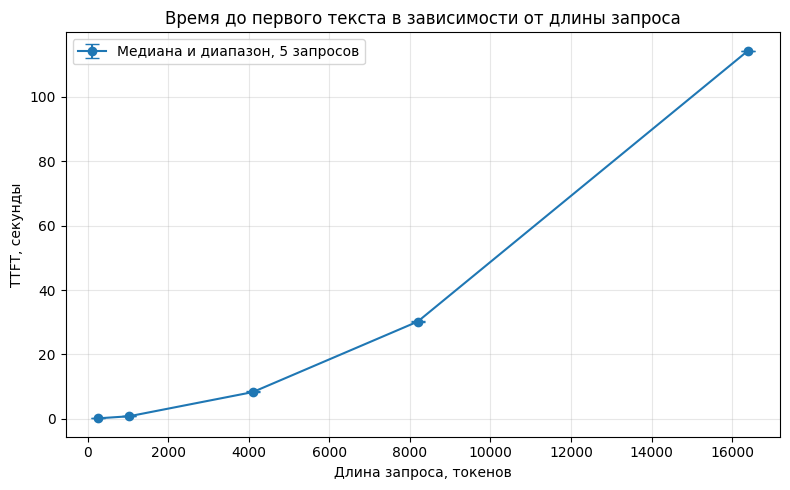

  256 токенов | TTFT: 0.170 с | оценка prefill: 1508.7 токенов/с
 1024 токенов | TTFT: 0.806 с | оценка prefill: 1269.9 токенов/с
 4096 токенов | TTFT: 8.311 с | оценка prefill: 492.8 токенов/с
 8192 токенов | TTFT: 30.194 с | оценка prefill: 271.3 токенов/с
16384 токенов | TTFT: 114.173 с | оценка prefill: 143.5 токенов/с

Таблица и рисунок сохранены: /content/lab1_artifacts/exp1/11d657f62c8d4c99ad2a45918523d100/analysis/b1adeb806f63454ca1d03043efeee314


In [22]:
# Анализ уже выполненного эксперимента — без новых запросов к модели.
import csv
import json
import math
import statistics
from pathlib import Path
from uuid import uuid4
import matplotlib.pyplot as plt

run_dir = Path(
    "/content/lab1_artifacts/exp1/11d657f62c8d4c99ad2a45918523d100"
)

records = [
    json.loads(line)
    for line in (run_dir / "results.jsonl").read_text(
        encoding="utf-8"
    ).splitlines()
    if line.strip()
]

assert len(records) == 25

# Пересчитываем метрики по исходным отметкам времени.
for record in records:
    assert record["status"] == "completed"
    assert record["kind"] == "experiment_1"
    assert record["output_tokens"] == 16
    assert record["prompt_tokens"] == record["target_prompt_tokens"]

    times = record["text_chunk_times"]
    ttft = times[0] - record["t0"]
    tpot = (times[-1] - times[0]) / (record["output_tokens"] - 1)
    e2e = times[-1] - record["t0"]

    assert math.isclose(ttft, record["ttft_s"], abs_tol=1e-9)
    assert math.isclose(tpot, record["tpot_s"], abs_tol=1e-9)
    assert math.isclose(e2e, record["e2e_s"], abs_tol=1e-9)

rows = []

for length in [256, 1024, 4096, 8192, 16384]:
    group = [r for r in records if r["prompt_tokens"] == length]
    assert len(group) == 5

    ttfts = [r["ttft_s"] for r in group]
    median_ttft = statistics.median(ttfts)

    rows.append({
        "prompt_tokens": length,
        "requests": len(group),
        "ttft_median_s": median_ttft,
        "ttft_min_s": min(ttfts),
        "ttft_max_s": max(ttfts),
        "tpot_median_ms": statistics.median(
            r["tpot_s"] for r in group
        ) * 1000,
        # Приближённая скорость prefill: TTFT включает и прочие задержки.
        "prefill_estimate_tokens_s": length / median_ttft,
    })

# Каждая версия анализа сохраняется отдельно.
output = run_dir / "analysis" / uuid4().hex
output.mkdir(parents=True)

with (output / "summary.csv").open(
    "w", encoding="utf-8", newline=""
) as file:
    writer = csv.DictWriter(file, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)

# Точки — медианы; вертикальные отрезки — минимум и максимум.
x = [r["prompt_tokens"] for r in rows]
y = [r["ttft_median_s"] for r in rows]
errors = [
    [r["ttft_median_s"] - r["ttft_min_s"] for r in rows],
    [r["ttft_max_s"] - r["ttft_median_s"] for r in rows],
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(
    x, y, yerr=errors, fmt="o-", capsize=5,
    label="Медиана и диапазон, 5 запросов"
)
ax.set_xlabel("Длина запроса, токенов")
ax.set_ylabel("TTFT, секунды")
ax.set_title("Время до первого текста в зависимости от длины запроса")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(output / "ttft_vs_prompt.png", dpi=300)
plt.show()
plt.close(fig)

for row in rows:
    print(
        f"{row['prompt_tokens']:5d} токенов | "
        f"TTFT: {row['ttft_median_s']:.3f} с | "
        f"оценка prefill: {row['prefill_estimate_tokens_s']:.1f} токенов/с"
    )

print("\nТаблица и рисунок сохранены:", output)

Следующий пункт методички — проверить пользу кеширования префикса.

Раньше запросы обрабатывались заново. Теперь включим кеш и трижды отправим один полностью одинаковый запрос на 8192 токена. Ожидаем, что повторные обращения начнут получать ответ быстрее.

Сначала только перезапустим сервер. Веса уже скачаны.

In [23]:
# Останавливаем прежний сервер и включаем кеширование префикса.
import shlex
import shutil
import subprocess
from pathlib import Path
from uuid import uuid4

session_dir = (
    Path("/content/lab1_artifacts/server_sessions") / uuid4().hex
)
session_dir.mkdir(parents=True)

# Берём прежнюю команду и меняем только настройку кеширования.
old_command = Path("/content/server_command.txt").read_text(encoding="utf-8")
command = shlex.split(old_command)

assert "--no-enable-prefix-caching" in command
command[command.index("--no-enable-prefix-caching")] = "--enable-prefix-caching"

# Дожидаемся остановки: два сервера одновременно не запускаем.
if server_process.poll() is None:
    server_process.terminate()
    server_process.wait(timeout=60)

# Сохраняем полный журнал первого запуска.
shutil.copyfile("/content/vllm.log", session_dir / "previous_server.log")

# Новая команда и новый журнал — отдельно от предыдущего запуска.
(session_dir / "command.txt").write_text(
    shlex.join(command), encoding="utf-8"
)
prefix_log = session_dir / "server.log"

with prefix_log.open("w", encoding="utf-8") as log:
    server_process = subprocess.Popen(
        command, stdout=log, stderr=subprocess.STDOUT
    )

print("Новый процесс:", server_process.pid)
print("Журнал:", prefix_log)

Новый процесс: 29108
Журнал: /content/lab1_artifacts/server_sessions/a1588ad40eb24f818f63da9db01561be/server.log


Затем выполняй ячейку проверки готовности.

In [25]:
import json
import urllib.request
import urllib.error

try:
    with urllib.request.urlopen(
        "http://127.0.0.1:8000/v1/models", timeout=5
    ) as response:
        models = json.load(response)

    print("СЕРВЕР ГОТОВ")
    print("Модели:", [item["id"] for item in models["data"]])

    # Проверяем настройку кеширования в журнале.
    for line in prefix_log.read_text(
        encoding="utf-8", errors="replace"
    ).splitlines():
        if "enable_prefix_caching" in line:
            print(line)

except urllib.error.URLError:
    print("Сервер пока не отвечает.")
    print("Статус процесса:", server_process.poll())
    print(prefix_log.read_text(
        encoding="utf-8", errors="replace"
    )[-5000:])

СЕРВЕР ГОТОВ
Модели: ['Qwen/Qwen3-4B-Instruct-2507']
(APIServer pid=29108) INFO 11-04 07:48:00 [startup.py:96] non-default args: {'model_tag': 'Qwen/Qwen3-4B-Instruct-2507', 'enable_auto_tool_choice': True, 'tool_call_parser': 'hermes', 'host': '127.0.0.1', 'model': 'Qwen/Qwen3-4B-Instruct-2507', 'dtype': 'half', 'max_model_len': 32768, 'gpu_memory_utilization': 0.9, 'enable_prefix_caching': True, 'max_num_seqs': 32}
(EngineCore pid=29199) INFO 11-04 07:48:15 [core.py:139] Initializing a V1 LLM engine (v0.33.0) with config: model='Qwen/Qwen3-4B-Instruct-2507', speculative_config=None, tokenizer='Qwen/Qwen3-4B-Instruct-2507', skip_tokenizer_init=False, tokenizer_mode=auto, revision=main, tokenizer_revision=main, trust_remote_code=False, dtype=torch.float16, max_seq_len=32768, download_dir=None, load_format=auto, tensor_parallel_size=1, pipeline_parallel_size=1, data_parallel_size=1, decode_context_parallel_size=1, dcp_comm_backend=ag_rs, disable_custom_all_reduce=False, quantization=Non